# Red de estaciones de transporte con grafos

## Andres Matias Carballo Rodriguez

## DDYA - 1101

## 1) Descripción del problema

El problema consiste en modelar y analizar una red de transporte urbano utilizando un grafo no dirigido. Cada estación representa un vértice y cada conexión directa entre dos estaciones representa una arista bidireccional. Para almacenar la red se utiliza una lista de adyacencia mediante un diccionario y listas sobre esta estructura se implementan la búsqueda en amplitud BFS mediante una cola para calcular los niveles de distancia y encontrar la ruta con menor cantidad de conexiones entre dos estaciones y la búsqueda en profundidad DFS para explorar las líneas de transporte hasta su punto final antes de retroceder, el sitema además permite elegir cualquier estación de partida, valida errores en nombres y permite incorporar nuevas estaciones conectadas bidireccionalmente.

## 2) Requerimientos

## Requerimientos funcionales:

RF1: El sistema debe representar la red de estaciones medante una lista de adyacencia usando diccionarios y listas   

RF2: Las conexiones de transporte deben guardarse de forma bidirecional, es decir en ambos sentidos porque es un grafo no dirigido

RF3: El programa debe permitir mostrar en pantalla la lista completa de estaciones con sus conexiones de transporte

RF4: El sistema debe implementar BFS usando una cola, mostrando el orden de visita y los grados de separacion desde una estacion inicial

RF5: El sistema debe implementar DFS usando recursion o una pila, avanzado por cada camino hasta el final antes de retroceder

RF6: El programa debe permitir que el usuario elija cualquier estacion como inicio de los recorridos,si la estacio no existe debe mostrar un mensaje de error claro

RF7: El sistema debe encontrar la ruta con menor cantidad de conexiones entre dos estaciones usando BFS e indicar los grados de separacion, si no hay conexion debe avisarlo

RF8: El sistema debe permitir registrar una estacion nueva y conectarla con al menos dos estaciones existentes mostrando luego la red actualizada y permitindo hacer recorridos y busquedas de nuevo

## Requerimientos no funcionales:

RNF1: El tiempo de ejecucion de BFS y DFS debe ser lineal, proporcional a la catidad de vertices mas la cantidad de aristas  

RNF2: El uso de memoria debe ser eficiente y limitarse al espacio necesario para la lista de adyacencia y las estructuras de cola, pila y visitados

RNF3: No se pueden utilizar librerias externas que resuelvan grafos, BFS o DFS de forma automatico

RNF4: Se debe usar una estructura de control para marcar a las estaciones visitadas y evitar ciclos infinitos o repeticiones

RNF5: El programa debe ser interactivo, facil de usar y no debe detenerse con errores si el usuario escribe nombres con espacios o mayusculas distintas

## 3) Historias de usuario

HU1: Explorar estaciones con BFS

Como usuario, quiero recorrer la red desde una estacon usando BFS, para ver a las conexiones de transporte por niveles y conocer su grado de separacion

Criterio de aceptacion: Al elegir a a la estacion central, se debe mostrar el orden de visita usando una cola y agrupar a las conexiones de transporte desde grado 0 hasta grado 3 sin repetir a otras estacionnes

HU2: Explorar estaciones con DFS

Como usuario, quiero hacer un recorrido en profundidad desde una estacion, para explorar un camino continuo hasta el fondo antes de regresar

Criterio de aceptacion: El programa debe avanzar por las ramas usando recursion o una pila, listando a todas las estacioes conectadas una sola vez  

HU3: Buscar la ruta mas corta

Como usuario, quiero indicar dos estaaciones, para encontrar el camino con menor cantidad de conexiones entre ellas

Criterio de aceptacion: Al buscar entre la estacion cetral y la estacion terminal, se debe mostrar la ruta con 3 grados de separacion usando BFS, o avisar si no existe conexion

HU4: Agregar una estacion nueva

Como usuario, quiero registrar una estacion nueva y conectarla con al menos dos estaciones

Criterio de aceptacion: Al agregar una estacion nueva por ejemplo aereopuerto conectada con las estaciones hospital y universidad, la conexion de transporte debe guardarse en ambos sentidos y permitir hacer de nuevo las busquedas sobre la red actualizada

## 4) Diagramas de flujo

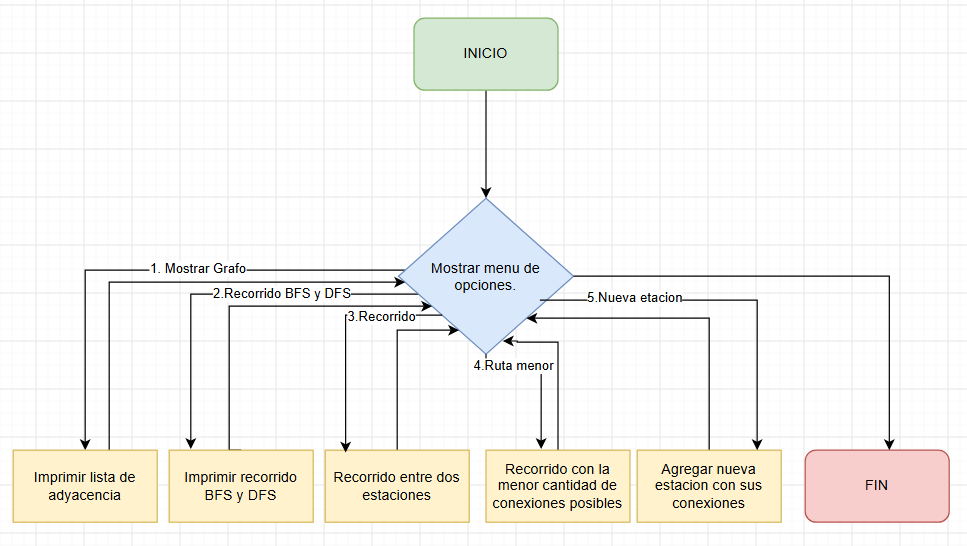

# Descripcion diagrama de flujo

El programa emplea un menu interactivo, es por esta razon que el diagrama de flujo sin importar la opcion retorna a mostrar el menu de opciones, a excepcion de la opcion 6, ya que esta cierra el menu y finaliza el programa.

### 5) Análisis de complejidad 

- Justificación:

Tanto en la busqueda por amplitud (BFS) como en la busqueda por profundidad (DFS), el algoritmo realiza dos tareas principales:   

Visita cada vertice de la red una sola vez, gracias a la lista de estaciones visitadas que impide repeticiones, esto toma un tiempo proporcional a la cantidad de estaciones: O(V) 

Cuando el algoritmo se para en cada estacion, revisa la lista de todas sus conexines de transporte, en un grafo no dirigido con lista de adyacencia, cada conexion se examina exactamente dos veces (una desde cada extremo), esto toma un tiempo proporcional a las conexiones: O(E)

Al sumar ambos costos, el tiempo total es de orden lineal respecto al tamaño completo del grafo: O(V + E)

- Función T[n]:

T(n) = O(V+E)

Mejor caso: Constante. Ω(1)

Cuando se busca una ruta entre dos estacioes y la estacion inicial es la misma estacion de destino, en este escenario el algoritmo no necesita recorrer el resto de la red

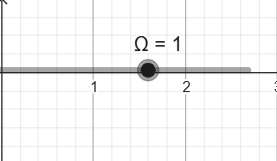

Peor caso: Lineal

Cuando el algoritmo debe recorrer toda la red de estaciones completa (como al ejecutar BFS o DFS para explorar todas las estaciones, o cuando se busca una ruta hacia una estacion que no tiene conexion o que se encuentra en el punto mas lejano de la red), aqui el algoritmo se ve obligado a visitar todos los vertices y a examiar todas las aristas existentes.

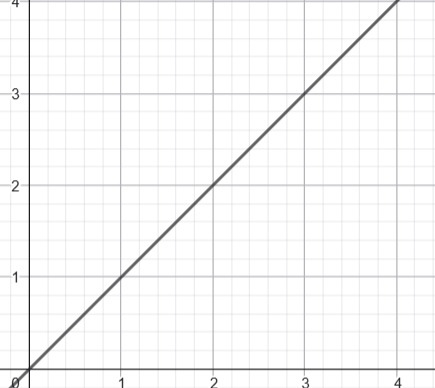

## 6) Código funcional

In [ ]:

red_transporte = {

    "Central": ["Norte", "Museo"],

    "Norte": ["Central", "Parque", "Universidad"],

    "Museo": ["Central", "Hospital"],

    "Parque": ["Norte"],

    "Universidad": ["Norte", "Terminal"],

    "Hospital": ["Museo", "Terminal"],

    "Terminal": ["Universidad", "Hospital"],
}


def mostrar_red(grafo):

  for estacion, conexiones in grafo.items():

    print(f"{estacion}: {', '.join(conexiones)}")


def bfs(grafo, inicio):

  cola = [inicio]

  visitados = [inicio]

  niveles = {inicio: 0}

  orden_visita = []

  while len(cola) > 0:

    actual = cola.pop(0)

    orden_visita.append(actual)

    for vecino in grafo[actual]:

      if vecino not in visitados:

        visitados.append(vecino)

        niveles[vecino] = niveles[actual] + 1

        cola.append(vecino)

  print("Recorrido posible")

  print(" -> ".join(orden_visita))

  print("\nNiveles de conexión:")

  max_nivel = max(niveles.values())

  for n in range(max_nivel + 1):

    estaciones_nivel = [e for e, dist in niveles.items() if dist == n]

    print(f"Nivel {n}: {', '.join(estaciones_nivel)}")

  return orden_visita, niveles


def dfs(grafo, actual, visitados=None):

  if visitados is None:

    visitados = []

  visitados.append(actual)

  for vecino in grafo[actual]:

    if vecino not in visitados:

      dfs(grafo, vecino, visitados)

  return visitados


def ruta_mas_corta(grafo, inicio, destino):

  cola = [[inicio]]

  visitados = [inicio]

  while len(cola) > 0:

    camino = cola.pop(0)

    estacion = camino[-1]

    if estacion == destino:

      print("Ruta encontrada:")

      print(" -> ".join(camino))

      print(f"Cantidad de conexiones: {len(camino) - 1}")

      return camino

    for vecino in grafo[estacion]:

      if vecino not in visitados:

        visitados.append(vecino)

        cola.append(camino + [vecino])

  print(f"No existe una ruta entre {inicio} y {destino}")

  return None


def agregar_estacion_interactivo(grafo):

  nueva = input("Nueva estación: ").strip().capitalize()

  con1 = input("Conectar con: ").strip().capitalize()

  con2 = input("Conectar con: ").strip().capitalize()

  if con1 not in grafo or con2 not in grafo:

    print(f"Error: Una o ambas estaciones ('{con1}', '{con2}') no existe")

    return

  grafo[nueva] = [con1, con2]

  grafo[con1].append(nueva)

  grafo[con2].append(nueva)

  print("\nred de transporte actualizada")

  mostrar_red(grafo)

  print(f"\nrecorrido BFS desde {nueva}")

  bfs(grafo, nueva)

  print(f"\nrecorrido DFS desde {nueva}")

  print(" -> ".join(dfs(grafo, nueva)))

  destino = (

      input(f"\nbuscar ruta desde {nueva} hacia: ").strip().capitalize()

  )

  if destino in grafo:

    ruta_mas_corta(grafo, nueva, destino)

  else:

    print(f"error, La estació '{destino}' no existe")


def main():

  while True:

    print("")

    print("   SISTEMA DE RED DE TRANSPORTE URBANO")

    print("")

    print("1. Mostrar red de estaciones")

    print("2. Recorridos BFS y DFS desde Central")

    print("3. Seleccionar estación inicial para recorridos")

    print("4. Encontrar ruta con menor conexiones")

    print("5. Agregar nueva estación y actualizar")

    print("6. Salir")

    print("")

    opcion = input("Seleccione una opción (1-6): ").strip()

    if opcion == "1":

      print("\nred de estacioes")

      mostrar_red(red_transporte)

    elif opcion == "2":

      print("\nrecorrido BFS desde Central")

      bfs(red_transporte, "Central")

      print("\nrecorrido DFS desde Central")

      print(" -> ".join(dfs(red_transporte, "Central")))

    elif opcion == "3":

      estacion = (

          input("\ningrese la estación inicial: ").strip().capitalize()

      )

      if estacion in red_transporte:

        print(f"\nrecorrido BFS desde {estacion}")

        bfs(red_transporte, estacion)

        print(f"\nrecorrido DFS desde {estacion}")

        print(" -> ".join(dfs(red_transporte, estacion)))

      else:

        print(f"error, La estación '{estacion}' no existe")

    elif opcion == "4":

      o = input("\nestación de origen: ").strip().capitalize()

      d = input("estación de destino: ").strip().capitalize()

      if o in red_transporte and d in red_transporte:

        ruta_mas_corta(red_transporte, o, d)

      else:

        print("error, una o ambas estaciones no existen")

    elif opcion == "5":

      agregar_estacion_interactivo(red_transporte)

    elif opcion == "6":

      print("saliendo del sistema")

      break

    else:

      print("opción inválida")

main()

## 7) Tests aplicados

In [ ]:
red_test = {
   "Central": ["Norte", "Museo"],
   "Norte": ["Central", "Parque", "Universidad"],
   "Museo": ["Central", "Hospital"],
   "Parque": ["Norte"],
   "Universidad": ["Norte", "Terminal"],
   "Hospital": ["Museo", "Terminal"],
   "Terminal": ["Universidad", "Hospital"],
}

assert len(red_test) == 7
assert "Norte" in red_test["Central"]
assert "Central" in red_test["Norte"]
assert "Hospital" in red_test["Terminal"]
assert "Terminal" in red_test["Hospital"]

_, niveles_central = bfs(red_test, "Central")
assert niveles_central["Central"] == 0
assert niveles_central["Norte"] == 1
assert niveles_central["Museo"] == 1
assert niveles_central["Parque"] == 2
assert niveles_central["Universidad"] == 2
assert niveles_central["Hospital"] == 2
assert niveles_central["Terminal"] == 3

recorrido_dfs = dfs(red_test, "Central")
assert len(recorrido_dfs) == 7
assert len(set(recorrido_dfs)) == 7
assert recorrido_dfs[0] == "Central"

ruta = ruta_mas_corta(red_test, "Central", "Terminal")
assert ruta is not None
assert len(ruta) - 1 == 3
assert ruta[0] == "Central" and ruta[-1] == "Terminal"

assert "Inexistente" not in red_test

nueva = "Aeropuerto"
red_test[nueva] = ["Terminal", "Hospital"]
red_test["Terminal"].append(nueva)
red_test["Hospital"].append(nueva)
assert len(red_test) == 8
assert "Aeropuerto" in red_test
assert "Aeropuerto" in red_test["Terminal"]
assert "Aeropuerto" in red_test["Hospital"]

ruta_aero = ruta_mas_corta(red_test, "Central", "Aeropuerto")
assert ruta_aero is not None
assert len(ruta_aero) - 1 == 3
assert ruta_aero[-1] == "Aeropuerto"
print("Todos los tests pasaron exitosamente")